Google Colab project - so paths may differ

In [3]:
import zipfile
zip_ref = zipfile.ZipFile("/content/melanoma-dataset.zip", 'r')
zip_ref.extractall()
zip_ref.close()

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [6]:
#normalizing
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

In [9]:
# Since the dataset has been extracted into Google Colab's workspace,
# we update the local paths to point to the /content/ directory structure.
import os

# Adjust these relative to where the zip extracts. Usually it extracts to './melanoma_cancer_dataset/' or similar.
train_path = "/content/melanoma_cancer_dataset/train"
test_path = "/content/melanoma_cancer_dataset/test"

# Fallback check to find the correct folders if the zip directory structure differs slightly
if not os.path.exists(train_path):
    train_path = "/content/train"
    test_path = "/content/test"

train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_data = val_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

print("Training Classes: ", train_data.class_indices)

Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Training Classes:  {'benign': 0, 'malignant': 1}


In [10]:
#making cnn model
model = Sequential()
model.add(Conv2D(32,(3,3),padding='valid',activation='relu',input_shape = (224,224,3)))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(64,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Conv2D(128,(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,177,281 (42.64 MB)

 Trainable params: 11,177,281 (42.64 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [13]:
history = model.fit(train_data,epochs=10,validation_data=val_data)
history

Epoch 1/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 166s 511ms/step - accuracy: 0.7748 - loss: 0.4606 - val_accuracy: 0.8560 - val_loss: 0.3307
Epoch 2/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 135s 449ms/step - accuracy: 0.8603 - loss: 0.3248 - val_accuracy: 0.9010 - val_loss: 0.2592
Epoch 3/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 137s 456ms/step - accuracy: 0.8775 - loss: 0.2988 - val_accuracy: 0.8880 - val_loss: 0.2640
Epoch 4/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 133s 443ms/step - accuracy: 0.8782 - loss: 0.2917 - val_accuracy: 0.8820 - val_loss: 0.2660
Epoch 5/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 146s 458ms/step - accuracy: 0.8835 - loss: 0.2801 - val_accuracy: 0.8960 - val_loss: 0.2504
Epoch 6/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 131s 436ms/step - accuracy: 0.8868 - loss: 0.2697 - val_accuracy: 0.8920 - val_loss: 0.2426
Epoch 7/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 134s 446ms/step - accuracy: 0.8885 - loss: 0.2605 - val_accuracy: 0.8950 - val_loss: 0.2446
Epoch 8/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 139s 463ms/step - accuracy: 0.8880 -

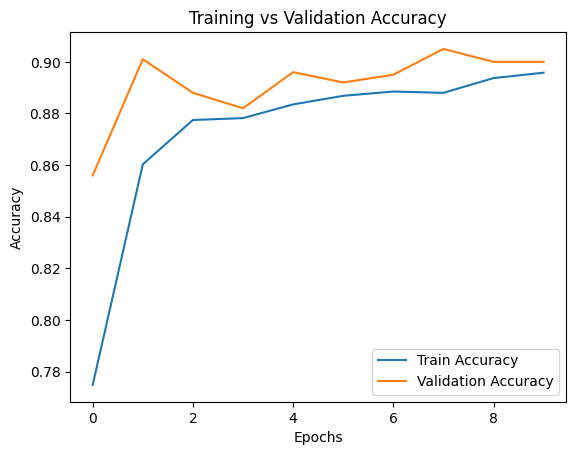

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')
plt.show()

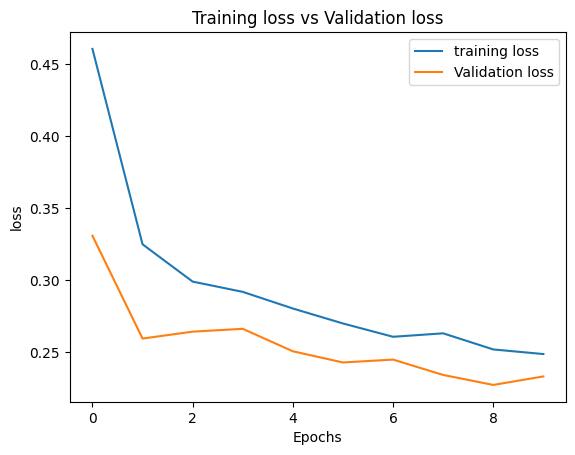

In [15]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.title('Training loss vs Validation loss')
plt.show()

In [18]:
from tensorflow.keras.preprocessing import image
import numpy as np

# 1. Load image
img_path = r"/content/melanoma_5040.jpg"
img = image.load_img(img_path, target_size=(224, 224))

# 2. Convert to array
img_array = image.img_to_array(img)

# 3. Normalize (same as training)
img_array = img_array / 255.0

# 4. Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# 5. Predict
prediction = model.predict(img_array)

# 6. Interpret result
if prediction[0][0] > 0.5:
    print("It is a melanoma⚠️")
else:
    print("It is a benign✅")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
It is a melanoma⚠️
